In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

In [3]:
df = pd.read_csv("IMDB_Dataset.csv",encoding="ISO-8859-1")
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [4]:
df.shape

(50000, 2)

In [5]:
df.columns

Index(['review', 'sentiment'], dtype='str')

In [8]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [9]:
df.tail()

,review,sentiment
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative
49999,No one expects the Star Trek movies to be high...,negative


In [10]:
df.describe(include='all')

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [11]:
df.dtypes

review       str
sentiment    str
dtype: object

In [13]:
df.isna().sum()

review       0
sentiment    0
dtype: int64

In [15]:
df1 = df['sentiment'].value_counts()
df1

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='sentiment'>

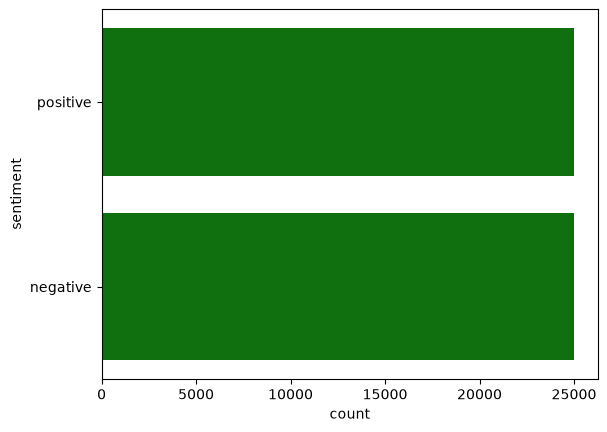

In [16]:
sns.countplot(df['sentiment'],color='g')

In [17]:
df['sentiment'] = df['sentiment'].replace("positive",1)
df['sentiment'] = df['sentiment'].replace("negative",0)

In [18]:
df['sentiment']

0        1
1        1
2        1
3        0
4        1
        ..
49995    1
49996    0
49997    0
49998    0
49999    0
Name: sentiment, Length: 50000, dtype: object

In [19]:
text = df.review

In [20]:
# Download resources
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\divya\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\divya\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [21]:
# Tokenization
from nltk.tokenize import TweetTokenizer

tk = TweetTokenizer()
reviews = text.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
reviews

0        One of the other reviewers has mentioned that ...
1        A wonderful little production . < br / > < br ...
2        I thought this was a wonderful way to spend ti...
3        Basically there's a family where a little boy ...
4        Petter Mattei's " Love in the Time of Money " ...
                               ...                        
49995    I thought this movie did a down right good job...
49996    Bad plot , bad dialogue , bad acting , idiotic...
49997    I am a Catholic taught in parochial elementary...
49998    I'm going to have to disagree with the previou...
49999    No one expects the Star Trek movies to be high...
Name: review, Length: 50000, dtype: str

In [22]:
# Removing special characters using regex
reviews = reviews.replace('[^a-zA-Z0-9]',' ',regex=True)
reviews

0        One of the other reviewers has mentioned that ...
1        A wonderful little production     br       br ...
2        I thought this was a wonderful way to spend ti...
3        Basically there s a family where a little boy ...
4        Petter Mattei s   Love in the Time of Money   ...
                               ...                        
49995    I thought this movie did a down right good job...
49996    Bad plot   bad dialogue   bad acting   idiotic...
49997    I am a Catholic taught in parochial elementary...
49998    I m going to have to disagree with the previou...
49999    No one expects the Star Trek movies to be high...
Name: review, Length: 50000, dtype: str

In [23]:
# Remove the words, the length should be less than 3
from nltk.tokenize import word_tokenize

reviews = reviews.apply(lambda x:' '.join([w for w in word_tokenize(x) if len(w)>=3]))
reviews


0        One the other reviewers has mentioned that aft...
1        wonderful little production The filming techni...
2        thought this was wonderful way spend time too ...
3        Basically there family where little boy Jake t...
4        Petter Mattei Love the Time Money visually stu...
                               ...                        
49995    thought this movie did down right good job was...
49996    Bad plot bad dialogue bad acting idiotic direc...
49997    Catholic taught parochial elementary schools n...
49998    going have disagree with the previous comment ...
49999    one expects the Star Trek movies high art but ...
Name: review, Length: 50000, dtype: str

In [24]:
# stemming and convert to lowercase
from nltk.stem import SnowballStemmer

data = SnowballStemmer('english')
reviews = reviews.apply(lambda x:[data.stem(i.lower()) for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))



In [25]:
# Remove the stopwords
from nltk.corpus import stopwords

stp = stopwords.words('english')
reviews = reviews.apply(lambda x:[i for i in tk.tokenize(x) if i not in stp]).apply(lambda x:' '.join(x))
reviews

0        one review mention watch episod hook right exa...
1        wonder littl product film techniqu veri unassu...
2        thought wonder way spend time hot summer weeke...
3        basic famili littl boy jake think zombi closet...
4        petter mattei love time money visual stun film...
                               ...                        
49995    thought movi right good job creativ origin fir...
49996    bad plot bad dialogu bad act idiot direct anno...
49997    cathol taught parochi elementari school nun ta...
49998    go disagre previous comment side maltin one se...
49999    one expect star trek movi high art fan expect ...
Name: review, Length: 50000, dtype: str

In [26]:
# Vectorization (Convert all text into numerical data)
from sklearn.feature_extraction.text import TfidfVectorizer

vector = TfidfVectorizer()
train_data = vector.fit_transform(reviews)
train_data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4697844 stored elements and shape (50000, 69196)>

In [38]:
y = df['sentiment'].astype(int).values
y
# y.shape

array([1, 1, 1, ..., 0, 0, 0])

In [39]:
df.dtypes

review          str
sentiment    object
dtype: object

In [40]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(train_data,y,test_size=0.30,random_state=42)

In [41]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(x_train,y_train)
y_pred = knn.predict(x_test)
y_pred

array([1, 1, 0, ..., 0, 1, 1])

In [42]:
from sklearn.metrics import accuracy_score

score = accuracy_score(y_test,y_pred)
score

0.7832

In [44]:
review = ["The movie is very nice"]
rev = vector.transform(review)
predict = knn.predict(rev)
predict


array([1])

In [49]:
print("Review: ",review[0])
if predict[0] == 1:
    print("The sentiment is: Positive 😊")
else:
    print("The sentiment is: Negative 😞")

Review:  The movie is very nice
The sentiment is: Positive 😊
